# 24. 실험 2 — Stellantis N.V.를 KAMP 조건으로 맞춘 검증
기본 평가: 시간순(2022~23년 14일 학습 → 2024년 5일 931타점 추천, 시험 차체는 학습 차체와 겹치지 않음). 모델 사양은 그대로다(raw PVC 10시드, D4, 결합).
조건(실행 전 고정):
- base: 조건 없음(재현 기준, 결합 10% = 17/51).
- (a) 불량률 낮추기: 불량 타점을 확률 0.1로 남겨(약 4.0% → 0.4%) 학습 개수와 시험 정답을 모두 줄인다. **100회**(요청 200회에서 축소: 1회 10시드 학습 약 18초). 난수 시드 1000+r.
- (b) 날짜 8개: 학습 14일 중 8일을 무작위로 골라 학습한다. **30조합**. 난수 시드 2000+r.
- (c1) 위치 효과 제거(입력): raw PVC 입력 7개와 D4의 파생 변수 9개를 위치별로 표준화한 뒤 같은 절차. 1회(10시드).
- (c2) 위치 효과 제거(채점): 모든 조건의 점수를 같은 위치 안 AUROC(같은 위치 타점끼리만 불량·정상 순위 비교)로도 채점.
- (abc): (a)+(b)+(c1) 동시 적용. **100회**. 난수 시드 3000+r.
지표: 날짜별 5·10·20% 예산에서 찾은 불량 수 / 남은 불량 수, 같은 수 무작위 기대값, AUROC, 같은 위치 안 AUROC.
95% 구간: 반복이 있는 조건은 반복 단위 복원추출(합의 비율), 1회 조건은 시험 차체 9대 복원추출.

In [1]:
import time, pickle, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
import br
from br import spec as S, validity as V, plot as P
from wl.metrics import inclusion_prob, within_loc_auroc
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 230)
X, day, cnt, y, _ = S.load_polito()
Xd9, *_ = S.load_polito("derived5")                 # 파생 9개(날짜 안 이탈 크기 변환 전)
P0 = wldata.load_polito(); loc, body = P0["loc"].values, P0.body.values
TR = np.array([d_ < "2024" for d_ in day]); TE = np.array([d_ >= "2024-02-01" for d_ in day])
tr_days = np.unique(day[TR]); te_idx = np.flatnonzero(TE)
X_loc = V.loc_standardize(X, loc); Xd9_loc = V.loc_standardize(Xd9, loc)
def d4_of(Xd):
    return S.day_transform(Xd, day, "absz").sum(axis=1).values[TE]
D4 = {"orig": d4_of(Xd9), "loc": d4_of(Xd9_loc)}
SEEDS = range(10)

def run(yv, days_used, Xin):
    trm = TR & np.isin(day, days_used)
    ub, bag = np.unique(day[trm], return_inverse=True)
    c_ = pd.Series(yv[trm]).groupby(day[trm]).sum().loc[ub].values.astype(int)
    return np.mean([S.fit_score("PVC MLP", Xin, bag, c_, trm, TE, s)[0] for s in SEEDS], 0)

PLAN = [("base", 0), ("c1", 0)] + [("b", r) for r in range(30)] + [("a", r) for r in range(100)] + [("abc", r) for r in range(100)]
cache = br.RES / "exp2_runs.pkl"
runs = pickle.load(open(cache, "rb")) if cache.exists() else {}
t0 = time.time()
for cond, r in PLAN:
    if (cond, r) in runs or time.time() - t0 > 510: continue
    yv, days_used, Xin, d4k = y.copy(), tr_days, X, "orig"
    if cond in ("a", "abc"):
        rng = np.random.default_rng((1000 if cond == "a" else 3000) + r)
        yv = (y.astype(bool) & (rng.random(len(y)) < 0.1)).astype(int)
    if cond in ("b", "abc"):
        rng2 = np.random.default_rng((2000 if cond == "b" else 3000) + r + 7)
        days_used = np.sort(rng2.choice(tr_days, 8, replace=False))
    if cond in ("c1", "abc"):
        Xin, d4k = X_loc, "loc"
    runs[(cond, r)] = dict(raw=run(yv, days_used, Xin), y=yv[TE], days=days_used, d4=d4k, n_tr_def=int(yv[TR & np.isin(day, days_used)].sum()))
    pickle.dump(runs, open(cache, "wb"))
print(f"학습: {sum(k in runs for k in PLAN)}/{len(PLAN)} ({time.time()-t0:.0f}초)")
DONE = all(k in runs for k in PLAN)

학습: 232/232 (264초)


## 결과

In [2]:
dt, lt, bt = day[TE], loc[TE], body[TE]
ud, gi = np.unique(dt, return_inverse=True); n = np.bincount(gi)
rk = lambda s: pd.Series(s).groupby(dt).rank(pct=True).values
def scores_of(R):
    return {"raw PVC": R["raw"], "D4": D4[R["d4"]], "결합": (rk(R["raw"]) + rk(D4[R["d4"]])) / 2}
def hits(s, yt, b):
    k = np.ceil(b * n - 1e-9); return (inclusion_prob(s, k, gi) * yt).sum(), (k / n * np.bincount(gi, weights=yt)).sum()
def wl_auc(s, yt):
    return within_loc_auroc(yt, s, lt) if 0 < yt.sum() < len(yt) else np.nan
ubt = np.unique(bt); rngb = np.random.default_rng(11)
Wb = np.stack([np.bincount(d_, minlength=len(ubt)) for d_ in rngb.integers(0, len(ubt), (3000, len(ubt)))])[:, np.searchsorted(ubt, bt)]

def summarize(cond):
    keys = [k for k in runs if k[0] == cond]
    rows = []
    for m in ["raw PVC", "D4", "결합"]:
        r = {"조건": cond, "모델": m, "반복": len(keys)}
        per = []   # 반복별 (예산별 포착, 무작위, 불량 수, AUROC, 위치 안 AUROC)
        for k in keys:
            R = runs[k]; s = scores_of(R)[m]; yt = R["y"]
            h = [hits(s, yt, b) for b in (.05, .1, .2)]
            per.append([x for hh in h for x in hh] + [yt.sum(), roc_auc_score(yt, s) if 0 < yt.sum() < len(yt) else np.nan, wl_auc(s, yt)])
        per = np.array(per, float)
        tot = per[:, 6].sum(); r["시험 불량(합)"] = int(tot)
        for j, b in enumerate((5, 10, 20)):
            hit, rnd = per[:, 2 * j].sum(), per[:, 2 * j + 1].sum()
            if len(keys) > 1:
                rng = np.random.default_rng(j); bs = []
                for _ in range(3000):
                    ii = rng.integers(0, len(keys), len(keys)); den = per[ii, 6].sum()
                    bs.append((per[ii, 2 * j].sum() - per[ii, 2 * j + 1].sum()) / den if den > 0 else np.nan)
                lo, hi = np.nanquantile(bs, [.025, .975])
            else:
                R = runs[keys[0]]; s = scores_of(R)[m]; yt = R["y"]; k_ = np.ceil(b / 100 * n - 1e-9)
                p_ = inclusion_prob(s, k_, gi); pr = (k_ / n)[gi]
                d_ = (Wb @ ((p_ - pr) * yt)) / (Wb @ yt); lo, hi = np.quantile(d_, [.025, .975])
            r[f"{b}% 포착/무작위"] = f"{hit:.1f}/{rnd:.1f}"
            r[f"{b}% 포착률−무작위 [95%]"] = f"{(hit - rnd) / tot * 100:+.1f}%p [{lo*100:+.1f}, {hi*100:+.1f}]"
        r["AUROC"] = round(np.nanmean(per[:, 7]), 3); r["같은 위치 안 AUROC"] = round(np.nanmean(per[:, 8]), 3)
        rows.append(r)
    return rows

if DONE:
    res = pd.DataFrame([r for c in ["base", "a", "b", "c1", "abc"] for r in summarize(c)])
    res.to_csv(br.RES / "exp2_conditions.csv", index=False, encoding="utf-8-sig")
    display(res[["조건", "모델", "반복", "시험 불량(합)", "5% 포착/무작위", "10% 포착/무작위", "10% 포착률−무작위 [95%]", "20% 포착/무작위", "20% 포착률−무작위 [95%]", "AUROC", "같은 위치 안 AUROC"]])
    display(res[["조건", "모델", "5% 포착률−무작위 [95%]"]])
    # 같은 위치 안 AUROC의 구간(1회 조건: 시험 차체 복원추출)
    rows = []
    for cond in ["base", "c1"]:
        R = runs[(cond, 0)]
        for m, s in scores_of(R).items():
            vals = []
            for _ in range(1000):
                bb = rngb.choice(ubt, len(ubt)); ii = np.concatenate([np.flatnonzero(bt == b_) for b_ in bb])
                yy = R["y"][ii]
                if 0 < yy.sum() < len(yy): vals.append(within_loc_auroc(yy, s[ii], lt[ii]))
            rows.append({"조건": cond, "모델": m, "같은 위치 안 AUROC": round(wl_auc(s, R["y"]), 3),
                         "95% 구간(차체 복원추출)": f"[{np.nanquantile(vals,.025):.3f}, {np.nanquantile(vals,.975):.3f}]"})
    wl = pd.DataFrame(rows); wl.to_csv(br.RES / "exp2_withinloc_ci.csv", index=False, encoding="utf-8-sig"); display(wl)

,조건,모델,반복,시험 불량(합),5% 포착/무작위,10% 포착/무작위,10% 포착률−무작위 [95%],20% 포착/무작위,20% 포착률−무작위 [95%],AUROC,같은 위치 안 AUROC
0,base,raw PVC,1,51,4.0/3.4,10.0/5.7,"+8.5%p [-2.9, +17.9]",21.0/10.3,"+21.0%p [+8.9, +29.1]",0.583,0.490
1,base,D4,1,51,9.0/3.4,14.0/5.7,"+16.4%p [+9.0, +21.6]",19.0/10.3,"+17.1%p [+5.4, +29.9]",0.709,0.519
2,base,결합,1,51,9.0/3.4,17.0/5.7,"+22.2%p [+7.8, +34.4]",21.0/10.3,"+21.0%p [+8.5, +29.9]",0.686,0.495
3,a,raw PVC,100,479,26.0/31.9,35.0/53.2,"-3.8%p [-6.1, -1.3]",78.0/96.6,"-3.9%p [-7.2, -0.2]",0.430,0.510
4,a,D4,100,479,81.0/31.9,132.0/53.2,"+16.5%p [+12.5, +20.6]",195.0/96.6,"+20.6%p [+16.5, +24.4]",0.700,0.517
5,a,결합,100,479,31.5/31.9,59.0/53.2,"+1.2%p [-2.2, +5.0]",116.2/96.6,"+4.1%p [-0.6, +9.1]",0.613,0.505
6,b,raw PVC,30,1530,154.0/101.3,260.0/169.6,"+5.9%p [+3.4, +8.5]",434.0/308.5,"+8.2%p [+4.6, +12.0]",0.541,0.489
7,b,D4,30,1530,270.0/101.3,420.0/169.6,"+16.4%p [+16.4, +16.4]",570.0/308.5,"+17.1%p [+17.1, +17.1]",0.709,0.519
8,b,결합,30,1530,197.5/101.3,346.7/169.6,"+11.6%p [+8.9, +14.4]",563.5/308.5,"+16.7%p [+13.3, +20.2]",0.672,0.503
9,c1,raw PVC,1,51,1.0/3.4,6.0/5.7,"+0.7%p [-9.4, +18.4]",11.0/10.3,"+1.4%p [-7.5, +14.5]",0.581,0.490


,조건,모델,5% 포착률−무작위 [95%]
0,base,raw PVC,"+1.2%p [-3.1, +4.9]"
1,base,D4,"+11.0%p [+6.4, +17.1]"
2,base,결합,"+11.0%p [+1.3, +18.0]"
3,a,raw PVC,"-1.2%p [-3.3, +1.1]"
4,a,D4,"+10.3%p [+7.0, +13.6]"
5,a,결합,"-0.1%p [-2.4, +2.4]"
6,b,raw PVC,"+3.4%p [+1.8, +5.1]"
7,b,D4,"+11.0%p [+11.0, +11.0]"
8,b,결합,"+6.3%p [+4.7, +8.0]"
9,c1,raw PVC,"-4.7%p [-5.2, -3.4]"


,조건,모델,같은 위치 안 AUROC,95% 구간(차체 복원추출)
0,base,raw PVC,0.490,"[0.311, 0.644]"
1,base,D4,0.519,"[0.412, 0.634]"
2,base,결합,0.495,"[0.369, 0.595]"
3,c1,raw PVC,0.490,"[0.290, 0.674]"
4,c1,D4,0.558,"[0.417, 0.722]"
5,c1,결합,0.519,"[0.385, 0.667]"


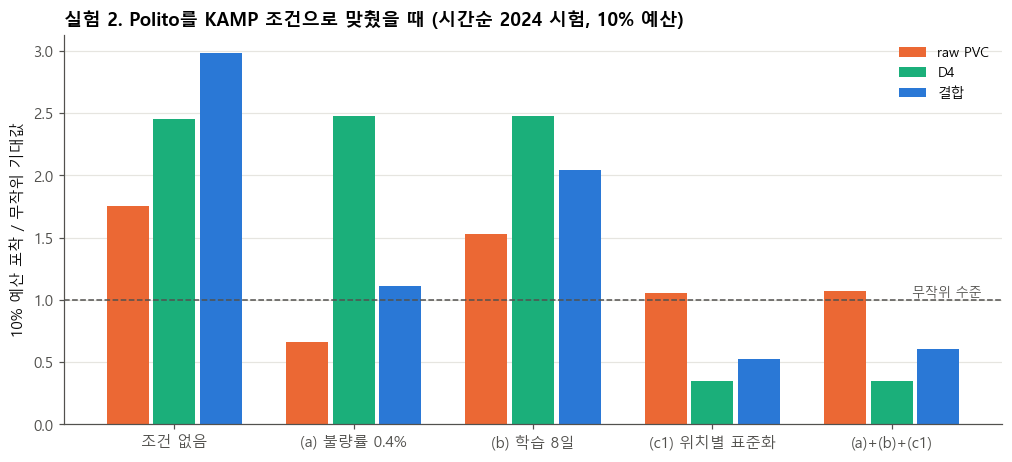

In [3]:
if DONE:
    fig, ax = plt.subplots(figsize=(11, 4.6))
    conds = ["base", "a", "b", "c1", "abc"]; names = {"base": "조건 없음", "a": "(a) 불량률 0.4%", "b": "(b) 학습 8일", "c1": "(c1) 위치별 표준화", "abc": "(a)+(b)+(c1)"}
    x = np.arange(len(conds)); w = .26
    for i, (m, col) in enumerate([("raw PVC", P.PAL[1]), ("D4", P.PAL[2]), ("결합", P.PAL[0])]):
        v = []
        for c in conds:
            r = res[(res.조건 == c) & (res.모델 == m)].iloc[0]
            h, rd = map(float, r["10% 포착/무작위"].split("/")); v.append(h / rd)
        ax.bar(x + (i - 1) * w, v, w * .9, color=col, label=m)
    ax.axhline(1, color=P.INK2, ls="--", lw=1); ax.text(len(conds) - .5, 1.03, "무작위 수준", color=P.INK2, fontsize=8.5, ha="right")
    ax.set_xticks(x); ax.set_xticklabels([names[c] for c in conds]); ax.set_ylabel("10% 예산 포착 / 무작위 기대값"); ax.grid(axis="x", visible=False)
    ax.set_title("실험 2. Stellantis N.V.를 KAMP 조건으로 맞췄을 때 (시간순 2024 시험, 10% 예산)", loc="left", fontweight="bold"); ax.legend(fontsize=9)
    P.save(fig, "21_exp2_conditions"); plt.show()